# Language identification: fine-tuning a multilingual BERT and comparing it with earlier models
Fine-tunes a BERT-family model on **your language-identification dataset from lab assignment 1** and compares it with:
**Logistic regression, MLP, LSTM, GRU and a FastText-style classifier.** All models use the **same train / validation / test split**, so the comparison is fair.

| Group | Input | Model |
|---|---|---|
| Logistic regression, MLP | character n-gram TF-IDF | softmax regression / 1 hidden layer |
| LSTM, GRU | character sequence | bidirectional recurrent encoder |
| FastText-style | hashed word + character n-grams | averaged n-gram embeddings → linear |
| **BERT (fine-tuned)** | subword tokens | `google/muril-base-cased` by default (any BERT-style model works, see config) |

> **Data:** the **IndicCorp v2** corpus (`ai4bharat/IndicCorpV2` on Hugging Face), one monolingual file per Indian language. The language is the label; a fixed number of sentences per language is streamed, so the full corpus is never downloaded. Use a **GPU** runtime.
>
> If you still have the *numbers* from your earlier models, put them in `EARLIER_RESULTS` (section 8).



## 1. Install dependencies

In [1]:
import sys, subprocess, importlib.util
need = {"transformers": "transformers", "sentencepiece": "sentencepiece", "sklearn": "scikit-learn",
        "pandas": "pandas", "numpy": "numpy", "matplotlib": "matplotlib", "tqdm": "tqdm", "torch": "torch", "datasets": "datasets"}
missing = [pkg for mod, pkg in need.items() if importlib.util.find_spec(mod) is None]
if missing:
    print("Installing:", missing)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
else:
    print("All requirements already installed.")

All requirements already installed.


## 2. Configuration

In [2]:
import os, re, time, json, glob, random, zlib, copy
import numpy as np, pandas as pd

# ---- IndicCorp v2 (https://huggingface.co/datasets/ai4bharat/IndicCorpV2) ----
ALL_LANGS = ["asm_Beng", "ben_Beng", "brx_Deva", "doi_Deva", "gom_Deva", "guj_Gujr", "hin_Deva", "kan_Knda",
             "kas_Arab", "mai_Deva", "mal_Mlym", "mar_Deva", "mni_Mtei", "npi_Deva", "ory_Orya", "pan_Guru",
             "san_Deva", "snd_Deva", "tam_Taml", "tel_Telu", "urd_Arab", "khasi", "santhali"]   # split names in the dataset
LANGS = ALL_LANGS          # or a subset, e.g. ["hin_Deva", "mar_Deva", "npi_Deva", "ben_Beng", "asm_Beng", "urd_Arab"]
SAMPLES_PER_LANG = 2000    # sentences streamed per language (raise for better scores, lower for speed)
MIN_CHARS, MAX_TEXT_CHARS = 10, 300   # keep sentence-like lines only

# BERT-style model. Any of these work for Indian languages:
#   "google/muril-base-cased"       MuRIL (17 Indian languages + transliteration)  <- default
#                                   (no brx, doi, gom, kha, mai, mni, sat: expect weaker results on those)
#   "xlm-roberta-base"              XLM-RoBERTa base
#   "bert-base-multilingual-cased"  mBERT
#   "ai4bharat/indic-bert"          IndicBERT (ALBERT-based, small)
MODEL_NAME = "google/muril-base-cased"
BERT_MAX_LEN, BERT_BATCH, BERT_EPOCHS, BERT_LR = 128, 32, 3, 3e-5

SEED = 42
random.seed(SEED); np.random.seed(SEED)
import torch, torch.nn as nn, torch.nn.functional as F
torch.manual_seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)
OUT_DIR = "langid_results"; os.makedirs(OUT_DIR, exist_ok=True)

device: cuda


## 3. Load the dataset (IndicCorp v2)
For each language the split of `ai4bharat/IndicCorpV2` (config `indiccorp_v2`) is **streamed**, shuffled with a buffer, filtered to sentence-length lines and the first `SAMPLES_PER_LANG` kept. The sample is cached to a CSV so re-runs are instant.


In [3]:
from datasets import load_dataset

CACHE = f"{OUT_DIR}/indiccorp_sample_{SAMPLES_PER_LANG}.csv"
if os.path.exists(CACHE):
    raw = pd.read_csv(CACHE)
    print("loaded cached sample:", CACHE)
else:
    rows = []
    for lang in LANGS:
        got = 0
        try:
            stream = load_dataset("ai4bharat/IndicCorpV2", "indiccorp_v2", split=lang, streaming=True)
            stream = stream.shuffle(seed=SEED, buffer_size=10_000)
            for ex in stream:
                t = re.sub(r"\s+", " ", ex["text"]).strip()
                if MIN_CHARS <= len(t) <= MAX_TEXT_CHARS:
                    rows.append((t, lang)); got += 1
                    if got >= SAMPLES_PER_LANG: break
        except Exception as e:
            print(f"  ! {lang}: {type(e).__name__}: {e}")
        print(f"{lang}: {got} sentences")
    raw = pd.DataFrame(rows, columns=["text", "label"])
    raw.to_csv(CACHE, index=False)

df = pd.DataFrame({"text": raw["text"].astype(str).str.replace(r"\s+", " ", regex=True).str.strip(),
                   "label": raw["label"].astype(str).str.strip()})
df = df[(df.text != "") & (df.text.str.lower() != "nan")].drop_duplicates(subset=["text"]).reset_index(drop=True)
vc = df.label.value_counts()
small = vc[vc < 10].index.tolist()
if small:
    print("Dropping classes with <10 samples:", small); df = df[~df.label.isin(small)]
df = df.reset_index(drop=True)
df["n_chars"] = df.text.str.len()

CLASSES = sorted(df.label.unique()); C = len(CLASSES)
label2id = {c: i for i, c in enumerate(CLASSES)}
df["y"] = df.label.map(label2id)
print(f"{len(df)} samples, {C} languages: {CLASSES}")
display(df.label.value_counts().to_frame("samples").T)
print(df.n_chars.describe().round(1).to_dict())


README.md:   0%|          | 0.00/4.01k [00:00<?, ?B/s]

asm_Beng: 2000 sentences
ben_Beng: 2000 sentences
brx_Deva: 2000 sentences
doi_Deva: 2000 sentences
gom_Deva: 2000 sentences
guj_Gujr: 2000 sentences
  ! hin_Deva: UnicodeDecodeError: 'utf-8' codec can't decode byte 0xb9 in position 0: invalid start byte
hin_Deva: 0 sentences
kan_Knda: 2000 sentences
kas_Arab: 2000 sentences
mai_Deva: 2000 sentences
mal_Mlym: 2000 sentences
mar_Deva: 2000 sentences
mni_Mtei: 2000 sentences
npi_Deva: 2000 sentences
ory_Orya: 2000 sentences
pan_Guru: 2000 sentences
san_Deva: 2000 sentences
snd_Deva: 2000 sentences
tam_Taml: 2000 sentences
tel_Telu: 2000 sentences
urd_Arab: 2000 sentences
khasi: 2000 sentences
santhali: 2000 sentences
42758 samples, 22 languages: ['asm_Beng', 'ben_Beng', 'brx_Deva', 'doi_Deva', 'gom_Deva', 'guj_Gujr', 'kan_Knda', 'kas_Arab', 'khasi', 'mai_Deva', 'mal_Mlym', 'mar_Deva', 'mni_Mtei', 'npi_Deva', 'ory_Orya', 'pan_Guru', 'san_Deva', 'santhali', 'snd_Deva', 'tam_Taml', 'tel_Telu', 'urd_Arab']


label,guj_Gujr,brx_Deva,khasi,ory_Orya,mar_Deva,kan_Knda,urd_Arab,pan_Guru,san_Deva,asm_Beng,...,ben_Beng,doi_Deva,gom_Deva,mai_Deva,tam_Taml,snd_Deva,tel_Telu,santhali,kas_Arab,mni_Mtei
samples,2000,2000,2000,2000,2000,2000,2000,1999,1999,1999,...,1994,1986,1985,1977,1969,1949,1923,1841,1768,1372


{'count': 42758.0, 'mean': 108.0, 'std': 82.3, 'min': 10.0, '25%': 39.0, '50%': 79.0, '75%': 170.0, 'max': 300.0}


## 4. Train / validation / test split (80 / 10 / 10, stratified) - shared by all models

In [4]:
from sklearn.model_selection import train_test_split
tr, tmp = train_test_split(df, test_size=0.2, stratify=df.y, random_state=SEED)
va, te  = train_test_split(tmp, test_size=0.5, stratify=tmp.y, random_state=SEED)
tr, va, te = [d.reset_index(drop=True) for d in (tr, va, te)]
SPLIT = {"train": tr, "val": va, "test": te}
Y = {k: v.y.values for k, v in SPLIT.items()}
TXT = {k: v.text.tolist() for k, v in SPLIT.items()}
print({k: len(v) for k, v in SPLIT.items()})
for k, v in SPLIT.items(): v.to_csv(f"{OUT_DIR}/{k}.csv", index=False)

{'train': 34206, 'val': 4276, 'test': 4276}


## 5. Shared utilities (training loop, metrics, result tracking)

In [5]:
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

results, preds = {}, {}      # model name -> metrics dict / test predictions

def n_params(m): return sum(p.numel() for p in m.parameters())

def predict(model, batch_fn, split, n, bs=512):
    model.eval(); out = []
    with torch.no_grad():
        for s in range(0, n, bs):
            idx = np.arange(s, min(n, s + bs))
            out.append(model(*batch_fn(split, idx)).argmax(-1).cpu().numpy())
    return np.concatenate(out)

def register(name, test_pred, train_time, params, infer_ms):
    y = Y["test"]
    results[name] = {"accuracy": accuracy_score(y, test_pred) * 100, "macro_f1": f1_score(y, test_pred, average="macro") * 100,
                     "weighted_f1": f1_score(y, test_pred, average="weighted") * 100,
                     "train_time_s": round(train_time, 1), "params_M": round(params / 1e6, 2), "infer_ms_per_sample": round(infer_ms, 3)}
    preds[name] = test_pred
    print(f"{name}: test accuracy {results[name]['accuracy']:.2f} | macro-F1 {results[name]['macro_f1']:.2f}")

def fit_torch(name, model, batch_fn, epochs, lr, bs=128, wd=0.0):
    """Generic mini-batch trainer; keeps the epoch with the best validation macro-F1."""
    model.to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    n = len(Y["train"]); best, best_state = -1, None; t0 = time.time()
    for ep in range(epochs):
        model.train(); perm = np.random.permutation(n); tot = 0.0
        for s in range(0, n, bs):
            idx = perm[s:s + bs]
            loss = F.cross_entropy(model(*batch_fn("train", idx)), torch.as_tensor(Y["train"][idx], device=device))
            opt.zero_grad(); loss.backward(); opt.step(); tot += loss.item() * len(idx)
        vp = predict(model, batch_fn, "val", len(Y["val"]))
        f1 = f1_score(Y["val"], vp, average="macro") * 100
        print(f"  [{name}] epoch {ep + 1}/{epochs} loss {tot / n:.4f} | val macro-F1 {f1:.2f}")
        if f1 > best: best, best_state = f1, copy.deepcopy(model.state_dict())
    model.load_state_dict(best_state)
    train_time = time.time() - t0
    t1 = time.time(); tp = predict(model, batch_fn, "test", len(Y["test"])); infer = (time.time() - t1) / len(Y["test"]) * 1000
    register(name, tp, train_time, n_params(model), infer)

## 6. Baseline models
### 6.1 Logistic regression and MLP on character n-gram TF-IDF
Logistic regression = a single softmax (linear) layer on TF-IDF features, trained with cross-entropy and L2 weight decay.

In [6]:
from sklearn.feature_extraction.text import TfidfVectorizer
tfidf = TfidfVectorizer(analyzer="char_wb", ngram_range=(1, 3), max_features=50000, sublinear_tf=True, dtype=np.float32)
XT = {"train": tfidf.fit_transform(TXT["train"]), "val": tfidf.transform(TXT["val"]), "test": tfidf.transform(TXT["test"])}
NF = XT["train"].shape[1]; print("TF-IDF features:", NF)

def tfidf_batch(split, idx):
    return (torch.from_numpy(XT[split][idx].toarray()).float().to(device),)

lr_model  = nn.Linear(NF, C)
mlp_model = nn.Sequential(nn.Linear(NF, 256), nn.ReLU(), nn.Dropout(0.3), nn.Linear(256, C))
fit_torch("Logistic Regression", lr_model,  tfidf_batch, epochs=8, lr=2e-3, wd=1e-4)
fit_torch("MLP",                 mlp_model, tfidf_batch, epochs=8, lr=1e-3, wd=1e-4)

TF-IDF features: 50000
  [Logistic Regression] epoch 1/8 loss 1.3110 | val macro-F1 95.07
  [Logistic Regression] epoch 2/8 loss 0.4124 | val macro-F1 96.76
  [Logistic Regression] epoch 3/8 loss 0.2530 | val macro-F1 96.90
  [Logistic Regression] epoch 4/8 loss 0.1850 | val macro-F1 96.91
  [Logistic Regression] epoch 5/8 loss 0.1470 | val macro-F1 96.89
  [Logistic Regression] epoch 6/8 loss 0.1224 | val macro-F1 96.89
  [Logistic Regression] epoch 7/8 loss 0.1051 | val macro-F1 97.03
  [Logistic Regression] epoch 8/8 loss 0.0922 | val macro-F1 97.13
Logistic Regression: test accuracy 96.45 | macro-F1 96.54
  [MLP] epoch 1/8 loss 0.6417 | val macro-F1 96.77
  [MLP] epoch 2/8 loss 0.0860 | val macro-F1 97.23
  [MLP] epoch 3/8 loss 0.0507 | val macro-F1 97.25
  [MLP] epoch 4/8 loss 0.0328 | val macro-F1 96.99
  [MLP] epoch 5/8 loss 0.0214 | val macro-F1 97.00
  [MLP] epoch 6/8 loss 0.0131 | val macro-F1 96.71
  [MLP] epoch 7/8 loss 0.0084 | val macro-F1 96.91
  [MLP] epoch 8/8 loss 0.0

### 6.2 LSTM and GRU on character sequences

In [7]:
MAX_CHARS = 200
from collections import Counter
ch_cnt = Counter(ch for t in TXT["train"] for ch in t[:MAX_CHARS])
char2id = {ch: i + 2 for i, (ch, c) in enumerate(ch_cnt.most_common()) if c >= 2}     # 0 = PAD, 1 = UNK
ENC = {k: [[char2id.get(ch, 1) for ch in t[:MAX_CHARS]] or [1] for t in v] for k, v in TXT.items()}
print("character vocabulary:", len(char2id) + 2)

def seq_batch(split, idx):
    seqs = [ENC[split][i] for i in idx]
    L = torch.tensor([len(s) for s in seqs])
    ids = torch.zeros(len(seqs), int(L.max()), dtype=torch.long)
    for i, s in enumerate(seqs): ids[i, :len(s)] = torch.tensor(s)
    return ids.to(device), L

class CharRNN(nn.Module):
    def __init__(self, cell, vocab, n_classes, emb=64, hid=128):
        super().__init__()
        self.emb = nn.Embedding(vocab, emb, padding_idx=0)
        self.rnn = (nn.LSTM if cell == "lstm" else nn.GRU)(emb, hid, batch_first=True, bidirectional=True)
        self.drop = nn.Dropout(0.3); self.out = nn.Linear(2 * hid, n_classes)
    def forward(self, ids, lengths):
        x = self.emb(ids)
        packed = nn.utils.rnn.pack_padded_sequence(x, lengths.cpu(), batch_first=True, enforce_sorted=False)
        h, _ = self.rnn(packed)
        h, _ = nn.utils.rnn.pad_packed_sequence(h, batch_first=True, total_length=ids.size(1))
        mask = (ids != 0).unsqueeze(-1).float()
        return self.out(self.drop((h * mask).sum(1) / mask.sum(1).clamp(min=1)))

fit_torch("LSTM", CharRNN("lstm", len(char2id) + 2, C), seq_batch, epochs=6, lr=2e-3)
fit_torch("GRU",  CharRNN("gru",  len(char2id) + 2, C), seq_batch, epochs=6, lr=2e-3)

character vocabulary: 1113
  [LSTM] epoch 1/6 loss 0.5828 | val macro-F1 89.05
  [LSTM] epoch 2/6 loss 0.2248 | val macro-F1 92.53
  [LSTM] epoch 3/6 loss 0.1734 | val macro-F1 93.75
  [LSTM] epoch 4/6 loss 0.1393 | val macro-F1 93.93
  [LSTM] epoch 5/6 loss 0.1166 | val macro-F1 94.27
  [LSTM] epoch 6/6 loss 0.1050 | val macro-F1 94.71
LSTM: test accuracy 94.13 | macro-F1 94.21
  [GRU] epoch 1/6 loss 0.4904 | val macro-F1 93.14
  [GRU] epoch 2/6 loss 0.1601 | val macro-F1 95.06
  [GRU] epoch 3/6 loss 0.1219 | val macro-F1 95.47
  [GRU] epoch 4/6 loss 0.0982 | val macro-F1 95.11
  [GRU] epoch 5/6 loss 0.0830 | val macro-F1 95.98
  [GRU] epoch 6/6 loss 0.0657 | val macro-F1 94.76
GRU: test accuracy 94.95 | macro-F1 95.09


### 6.3 FastText-style classifier
Same idea as fastText: every text is represented by its **word unigrams plus character n-grams (2-4) of each word**, hashed into buckets; the n-gram embeddings are **averaged** and fed to one linear layer (implemented in PyTorch with `EmbeddingBag`).

In [8]:
BUCKETS, FT_DIM = 2 ** 18, 64

def ngram_ids(text):
    ids = []
    for w in text[:400].lower().split():
        ids.append(zlib.crc32(("w:" + w).encode()) % BUCKETS)
        wb = f"<{w}>"
        for n in (2, 3, 4):
            ids += [zlib.crc32(("c:" + wb[i:i + n]).encode()) % BUCKETS for i in range(len(wb) - n + 1)]
    return ids or [0]

FTI = {k: [ngram_ids(t) for t in v] for k, v in TXT.items()}

def ft_batch(split, idx):
    seqs = [FTI[split][i] for i in idx]
    offsets = torch.tensor([0] + [len(s) for s in seqs[:-1]]).cumsum(0)
    return torch.tensor([i for s in seqs for i in s]).to(device), offsets.to(device)

class FastTextLike(nn.Module):
    def __init__(self, n_classes):
        super().__init__()
        self.emb = nn.EmbeddingBag(BUCKETS, FT_DIM, mode="mean"); self.out = nn.Linear(FT_DIM, n_classes)
    def forward(self, flat, offsets): return self.out(self.emb(flat, offsets))

fit_torch("FastText-style", FastTextLike(C), ft_batch, epochs=10, lr=5e-3, bs=128)

  [FastText-style] epoch 1/10 loss 0.8603 | val macro-F1 95.42
  [FastText-style] epoch 2/10 loss 0.0897 | val macro-F1 96.75
  [FastText-style] epoch 3/10 loss 0.0379 | val macro-F1 96.73
  [FastText-style] epoch 4/10 loss 0.0175 | val macro-F1 96.89
  [FastText-style] epoch 5/10 loss 0.0084 | val macro-F1 96.98
  [FastText-style] epoch 6/10 loss 0.0044 | val macro-F1 96.91
  [FastText-style] epoch 7/10 loss 0.0028 | val macro-F1 96.98
  [FastText-style] epoch 8/10 loss 0.0018 | val macro-F1 96.91
  [FastText-style] epoch 9/10 loss 0.0013 | val macro-F1 96.89
  [FastText-style] epoch 10/10 loss 0.0011 | val macro-F1 96.91
FastText-style: test accuracy 96.23 | macro-F1 96.29


## 7. Fine-tune BERT
The pretrained encoder plus a classification head is fine-tuned end-to-end (AdamW, linear warm-up/decay schedule, mixed precision on GPU). The epoch with the best **validation macro-F1** is kept and evaluated once on the test set.

In [9]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
bert = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=C, id2label={i: c for i, c in enumerate(CLASSES)}, label2id=label2id).to(device)
print(f"{MODEL_NAME}: {n_params(bert) / 1e6:.1f}M parameters")

def bert_batch(split, idx):
    enc = tokenizer([TXT[split][i] for i in idx], truncation=True, max_length=BERT_MAX_LEN, padding=True, return_tensors="pt")
    return {k: v.to(device) for k, v in enc.items()}

@torch.no_grad()
def bert_predict(split, bs=128):
    bert.eval(); out = []
    for s in range(0, len(Y[split]), bs):
        idx = np.arange(s, min(len(Y[split]), s + bs))
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(device == "cuda")):
            out.append(bert(**bert_batch(split, idx)).logits.argmax(-1).cpu().numpy())
    return np.concatenate(out)

def fine_tune_bert(epochs=BERT_EPOCHS, lr=BERT_LR, bs=BERT_BATCH):
    n = len(Y["train"]); steps = epochs * ((n + bs - 1) // bs)
    opt = torch.optim.AdamW(bert.parameters(), lr=lr, weight_decay=0.01)
    sched = get_linear_schedule_with_warmup(opt, int(0.06 * steps), steps)
    use_amp = device == "cuda"
    try:    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    except AttributeError: scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
    best, best_state, t0 = -1, None, time.time()
    for ep in range(epochs):
        bert.train(); perm = np.random.permutation(n); tot = 0.0
        for k, s in enumerate(range(0, n, bs)):
            idx = perm[s:s + bs]
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=use_amp):
                logits = bert(**bert_batch("train", idx)).logits
            loss = F.cross_entropy(logits.float(), torch.as_tensor(Y["train"][idx], device=device))
            opt.zero_grad(); scaler.scale(loss).backward(); scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(bert.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step(); tot += loss.item() * len(idx)
            if k % 200 == 0: print(f"    epoch {ep + 1} step {k}/{(n + bs - 1) // bs} loss {loss.item():.4f}")
        f1 = f1_score(Y["val"], bert_predict("val"), average="macro") * 100
        print(f"[BERT] epoch {ep + 1}/{epochs} train loss {tot / n:.4f} | val macro-F1 {f1:.2f}")
        if f1 > best: best, best_state = f1, {k: v.detach().cpu().clone() for k, v in bert.state_dict().items()}
    bert.load_state_dict(best_state)
    return time.time() - t0

bert_time = fine_tune_bert()
t1 = time.time(); bert_test_pred = bert_predict("test"); infer = (time.time() - t1) / len(Y["test"]) * 1000
register(f"BERT ({MODEL_NAME.split('/')[-1]})", bert_test_pred, bert_time, n_params(bert), infer)

config.json:   0%|          | 0.00/411 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/206 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/3.16M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/113 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  953MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

... (2 outputs left out)

google/muril-base-cased: 237.6M parameters


model.safetensors: reconstructing file:   0%|          |  0.00B /  953MB            

model.safetensors: downloading bytes:           |  0.00B            

    epoch 1 step 0/1069 loss 3.0919
    epoch 1 step 200/1069 loss 2.8445
    epoch 1 step 400/1069 loss 2.1210
    epoch 1 step 600/1069 loss 1.4142
    epoch 1 step 800/1069 loss 0.9042
    epoch 1 step 1000/1069 loss 0.4043
[BERT] epoch 1/3 train loss 1.7091 | val macro-F1 87.06
    epoch 2 step 0/1069 loss 0.3600
    epoch 2 step 200/1069 loss 0.2976
    epoch 2 step 400/1069 loss 0.1465
    epoch 2 step 600/1069 loss 0.1888
    epoch 2 step 800/1069 loss 0.2310
    epoch 2 step 1000/1069 loss 0.1382
[BERT] epoch 2/3 train loss 0.2273 | val macro-F1 94.65
    epoch 3 step 0/1069 loss 0.1447
    epoch 3 step 200/1069 loss 0.1777
    epoch 3 step 400/1069 loss 0.0669
    epoch 3 step 600/1069 loss 0.1465
    epoch 3 step 800/1069 loss 0.2032
    epoch 3 step 1000/1069 loss 0.2474
[BERT] epoch 3/3 train loss 0.1216 | val macro-F1 95.32
BERT (muril-base-cased): test accuracy 95.49 | macro-F1 95.09


## 8. Comparison of all models
If you still have the numbers of the models from lab assignment 1, add them to `EARLIER_RESULTS` (accuracy and macro-F1 in %) to list them next to the models retrained here.

Test set: 4276 samples, 22 languages


,accuracy,macro_f1,weighted_f1,params_M,train_time_s,infer_ms_per_sample
MLP,96.59,96.68,96.62,12.81,34.7,0.14
Logistic Regression,96.45,96.54,96.48,1.10,24.1,0.14
FastText-style,96.23,96.29,96.23,16.78,37.8,0.05
GRU,94.95,95.09,95.01,0.23,95.9,0.06
BERT (muril-base-cased),95.49,95.09,95.50,237.57,711.4,1.35
LSTM,94.13,94.21,94.11,0.28,100.3,0.06


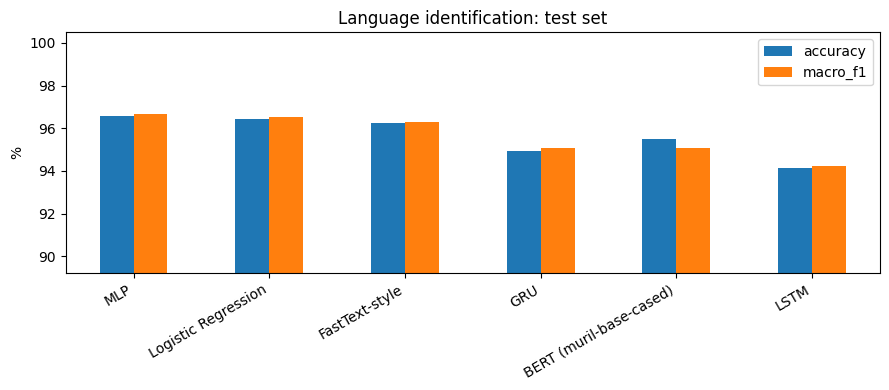

In [10]:
EARLIER_RESULTS = {
    # "Logistic Regression (lab 1)": {"accuracy": 0.0, "macro_f1": 0.0},
    # "LSTM (lab 1)":                {"accuracy": 0.0, "macro_f1": 0.0},
}

import matplotlib.pyplot as plt
res = pd.DataFrame(results).T
res = res[["accuracy", "macro_f1", "weighted_f1", "params_M", "train_time_s", "infer_ms_per_sample"]].sort_values("macro_f1", ascending=False).round(2)
res.to_csv(f"{OUT_DIR}/model_comparison.csv")
print(f"Test set: {len(Y['test'])} samples, {C} languages"); display(res)
if EARLIER_RESULTS: display(pd.DataFrame(EARLIER_RESULTS).T.round(2))

ax = res[["accuracy", "macro_f1"]].plot(kind="bar", figsize=(9, 4), ylim=(max(0, res["macro_f1"].min() - 5), 100.5))
ax.set_ylabel("%"); ax.set_title("Language identification: test set"); plt.xticks(rotation=30, ha="right"); plt.tight_layout()
plt.savefig(f"{OUT_DIR}/model_comparison.png", dpi=150); plt.show()

## 9. Error analysis: per-language results, confusions and text length

In [14]:
best_name = res.index[0]
bert_name = [k for k in results if k.startswith("BERT")][0]

print("Per-language report for", bert_name)
print(classification_report(Y["test"], preds[bert_name], target_names=CLASSES, digits=3))

cm = confusion_matrix(Y["test"], preds[bert_name])

off = [(CLASSES[i], CLASSES[j], int(cm[i, j]))
       for i in range(C) for j in range(C)
       if i != j and cm[i, j] > 0]

print("Most confused pairs (true -> predicted, count):",
      sorted(off, key=lambda x: -x[2])[:10])

# Accuracy by text length
bounds, labels = [0, 20, 50, 100, 10**9], ["<=20 chars", "21-50", "51-100", ">100"]
bucket = pd.cut(te.n_chars, bounds, labels=labels)

by_len = pd.DataFrame({
    m: pd.Series(p == Y["test"]).groupby(bucket.values, observed=False).mean() * 100
    for m, p in preds.items()
}).round(2)

by_len.insert(0, "n_test",
              pd.Series(bucket.values).value_counts().reindex(labels).values)

print("Test accuracy (%) by text length")
display(by_len)

# Examples where BERT is wrong
wrong = te[preds[bert_name] != Y["test"]].copy()
wrong["predicted"] = [CLASSES[i] for i in preds[bert_name][wrong.index]]

display(wrong[["text", "label", "predicted"]].head(10))

Per-language report for BERT (muril-base-cased)
              precision    recall  f1-score   support

    asm_Beng      1.000     0.995     0.997       200
    ben_Beng      0.995     1.000     0.998       200
    brx_Deva      0.970     0.980     0.975       200
    doi_Deva      0.921     0.935     0.928       199
    gom_Deva      0.801     0.854     0.826       198
    guj_Gujr      1.000     1.000     1.000       200
    kan_Knda      1.000     1.000     1.000       200
    kas_Arab      1.000     1.000     1.000       176
       khasi      0.995     0.995     0.995       200
    mai_Deva      0.949     0.949     0.949       198
    mal_Mlym      1.000     0.995     0.997       200
    mar_Deva      0.870     0.835     0.852       200
    mni_Mtei      0.632     0.788     0.701       137
    npi_Deva      1.000     0.975     0.987       200
    ory_Orya      1.000     1.000     1.000       200
    pan_Guru      1.000     1.000     1.000       200
    san_Deva      1.000     0.990

,n_test,Logistic Regression,MLP,LSTM,GRU,FastText-style,BERT (muril-base-cased)
<=20 chars,369,89.97,90.79,87.26,87.26,88.08,85.09
21-50,1161,95.35,95.43,91.30,93.02,94.83,94.66
51-100,914,96.83,96.94,95.51,95.95,96.94,96.50
>100,1832,98.25,98.31,96.62,97.22,98.42,97.60


,text,label,predicted
7,रामायण खरेच उत्कृष्ट मालिका आहे. सर्व कलाकारां...,gom_Deva,mar_Deva
12,"मुझे प्यार है,उस गोरे कागज से",brx_Deva,doi_Deva
25,अमने आला नाडू मडो,doi_Deva,gom_Deva
40,टुरना जि’यां इ’नें सखाया,doi_Deva,brx_Deva
59,"स्थावर मालमत्तेत (घर, फ्लॅट, जमीन, इ) केलेली ग...",gom_Deva,mar_Deva
60,ꯐꯨꯡꯒꯥꯋꯥꯔꯤ.,mni_Mtei,santhali
91,"!style=""padding-right:15px;""|प्रशासनिक-राजधानी",san_Deva,doi_Deva
99,ᱜᱚᱵᱽᱨᱚᱱᱚᱣᱟᱯᱟᱨᱟ,santhali,mni_Mtei
122,"""ꯏꯃꯣꯢꯅꯨ ꯏꯔꯥꯠꯄ"" (""ꯏꯃꯣꯏꯅꯨ ꯏꯔꯥꯠꯄ"") ꯑꯁꯤ ꯂꯥꯢꯔꯦꯝꯕꯤ ꯏ...",mni_Mtei,santhali
129,भाजपाशी लागेबांधे असणार्‍यांची प्रकरणे यांनी ब...,gom_Deva,mar_Deva


### Result analysis (complete after your run)

Use the tables and plots above, for example:

1. **Overall ranking:** list accuracy and macro-F1 for LR, MLP, LSTM, GRU, FastText-style and BERT. Is BERT clearly better? Language identification is often *easy* for character n-gram models, so the gap may be small; say whether the extra cost of BERT (parameters, training time, inference time in the table) is justified.
2. **Closely related languages:** use the confusion matrix and the most-confused pairs. Languages that share a script or vocabulary (e.g. Hindi/Marathi/Nepali in Devanagari, Hindi/Urdu, Assamese/Bengali) are the usual errors; compare which models resolve them better.
3. **Short texts:** compare the accuracy-by-length table. Short inputs give few characters or tokens to decide on, so all models drop; check whether pretrained BERT degrades less than the models trained from scratch.
4. **Model families:** n-gram models (LR, MLP, FastText) capture character and word cues directly and are very fast; LSTM/GRU read characters in order; BERT brings pretrained multilingual knowledge and sub-word tokenisation, and generalises to words never seen in training. Relate your numbers to these differences.
5. **Pretrained model choice:** mention the model you used (MuRIL / XLM-R / mBERT / IndicBERT), the languages it covers, and whether any language in your dataset is not covered by its pretraining.
6. **Limitations:** a single run per model (no variance estimate), one split, hyper-parameters not tuned, and the quality of the dataset's labels (e.g. code-mixed or transliterated sentences) affects every model.